# Threshold curves — `biased_bell_v2` & `biased_bell_v3`

Per-direction logical-error-rate vs `p` curves for the Bell-mediated noise models.
Both v2 and v3 are loaded together; each direction gets one subplot with the two
models drawn as separate curves (colored by model, linestyle by distance).

Each direction is either:

- **bias** `β` → `p_bell_z = β · p` (sweep `p`), or
- **fixed `p_bell_z`** → `p_bell_z` held constant while `p` sweeps.

Reads CSVs written by `tools/decode.py` (preamble `threshold_bell`).
Mirrors `threshold_comparison.ipynb` and `threshold_3d_surface.ipynb` in style.

In [7]:
import sys
import ast
import glob
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / 'src'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from threshold_fit import locate_threshold, fit_threshold

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [8]:
CSV_GLOB = '../out/collection/threshold_bell,*.csv'
NOISE_MODELS = ['biased_bell_v2', 'biased_bell_v3']  # plotted side by side

files = sorted(glob.glob(CSV_GLOB))
if not files:
    raise FileNotFoundError(f'No files matched: {CSV_GLOB}')
print(f'Loading {len(files)} file(s):')
for f in files:
    print(f'  {f}')

df = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)

# Merge repeated runs by strong_id (same circuit + decoder).
df = df.groupby('strong_id').agg({
    'shots': 'sum',
    'errors': 'sum',
    'discards': 'sum',
    'seconds': 'sum',
    'decoder': 'first',
    'json_metadata': 'first',
}).reset_index()

# Pull metadata columns we'll group/plot on.
def _parse(meta):
    return ast.literal_eval(meta) if isinstance(meta, str) else dict(meta)

meta = df['json_metadata'].apply(_parse)
for col in [
    'p', 'p_bell_z', 'direction_kind', 'direction_value',
    'bias', 'p_bell_z_fixed', 'expected_distance', 'rounds', 'k',
    'noise_model',
]:
    df[col] = meta.apply(lambda m, c=col: m.get(c))

df = df[df['noise_model'].isin(NOISE_MODELS)].reset_index(drop=True)

# A single string label per direction, used for grouping + titles + filenames.
def _direction_label(row):
    if row['direction_kind'] == 'bias':
        b = row['direction_value']
        return f'bias={int(b) if b == int(b) else b:g}'
    return f'pbz={row["direction_value"]:.4g}'

df['direction'] = df.apply(_direction_label, axis=1)
print(
    f'{len(df)} rows, '
    f'noise_models={sorted(df["noise_model"].unique())}, '
    f'{df["direction"].nunique()} directions, '
    f'distances={sorted(df["expected_distance"].dropna().unique())}'
)
print('rows per (noise_model, direction):')
print(df.groupby(['noise_model', 'direction']).size().unstack(fill_value=0))

Loading 1 file(s):
  ../out/collection/threshold_bell,2026-06-23.csv
1377 rows, noise_models=['biased_bell_v2', 'biased_bell_v3'], 12 directions, distances=[np.int64(3), np.int64(5), np.int64(7)]
rows per (noise_model, direction):
direction       bias=0  bias=1  bias=10  bias=100  bias=2  bias=20  bias=3  \
noise_model                                                                  
biased_bell_v2      87      87       87        63      48       48      87   
biased_bell_v3       0      48       48        39      48       48      48   

direction       bias=30  bias=5  bias=50  pbz=0.001  pbz=0.01  
noise_model                                                    
biased_bell_v2       87      48       45         87        87  
biased_bell_v3       48      48       45         48        48  


In [9]:
# Fit a threshold per (noise_model, direction). Same pipeline as
# threshold_3d_surface.ipynb: convert per-circuit logical error rate to a
# per-d-rounds, per-observable rate, then run the locate -> quadratic-FSS fit.

N_PER_SIDE = 2          # 5-point window around p_init
LOGICAL_CUTOFF = 0.3    # drop saturated points

fit_rows = []
for (noise_model, direction_name), grp in df.groupby(['noise_model', 'direction']):
    p_arr = grp['p'].to_numpy(dtype=float)
    d_arr = grp['expected_distance'].to_numpy(dtype=float)
    rounds_arr = grp['rounds'].to_numpy(dtype=float)
    k_arr = grp['k'].to_numpy(dtype=float)
    shots_arr = grp['shots'].to_numpy(dtype=float)
    errors_arr = grp['errors'].to_numpy(dtype=float)

    valid = (
        (shots_arr > 0)
        & (errors_arr > 0)
        & (errors_arr < shots_arr * LOGICAL_CUTOFF)
    )
    pL_total = np.where(valid, errors_arr / np.maximum(shots_arr, 1), np.nan)
    sigma_total = np.where(
        valid,
        np.sqrt(
            np.clip(pL_total * (1 - pL_total), 0, None)
            / np.maximum(shots_arr, 1)
        ),
        np.nan,
    )

    # Per-round, per-observable single-event rate.
    scale = d_arr / (rounds_arr * np.maximum(k_arr, 1))
    pL = 1 - (1 - pL_total) ** scale
    sigma = sigma_total * scale * (1 - pL_total) ** (scale - 1)

    p_init = locate_threshold(p_arr, d_arr, pL)
    if p_init is None:
        continue
    try:
        fit = fit_threshold(
            p_arr, d_arr, pL,
            sigma=sigma,
            p_init=p_init,
            n_per_side=N_PER_SIDE,
        )
    except Exception as exc:
        print(f'[skip] {noise_model} / {direction_name}: {exc}')
        continue
    if fit is None:
        continue

    direction_kind = grp['direction_kind'].iloc[0]
    bias = grp['bias'].iloc[0]
    p_bell_z_fixed = grp['p_bell_z_fixed'].iloc[0]
    fit_rows.append({
        'noise_model': noise_model,
        'direction': direction_name,
        'direction_kind': direction_kind,
        'bias': bias,
        'p_bell_z_fixed': p_bell_z_fixed,
        'p_th': fit.p_th,
        'p_th_err': fit.p_th_err,
        'mu': fit.mu,
        'mu_err': fit.mu_err,
        'p_init': fit.p_init,
        'n_points': fit.n_points,
    })

fits_df = pd.DataFrame(fit_rows)

# Sort: noise_model, then biases first (numeric), then fixed pbz (numeric).
fits_df['_sort'] = (
    fits_df['direction_kind'].map({'bias': 0, 'pbz': 1}) * 1e9
    + fits_df['bias'].fillna(0).astype(float)
    + fits_df['p_bell_z_fixed'].fillna(0).astype(float) * 1e3
)
fits_df = (
    fits_df.sort_values(['noise_model', '_sort'])
            .drop(columns='_sort')
            .reset_index(drop=True)
)
fits_df

,noise_model,direction,direction_kind,bias,p_bell_z_fixed,p_th,p_th_err,mu,mu_err,p_init,n_points
0,biased_bell_v2,bias=0,bias,0.0,NaN,0.002418,2.159251e-05,0.910499,0.044097,0.002512,15
1,biased_bell_v2,bias=1,bias,1.0,NaN,0.002047,1.233021e-05,0.971927,0.035426,0.002154,14
2,biased_bell_v2,bias=2,bias,2.0,NaN,0.001701,2.051408e-05,0.756509,0.026000,0.001585,13
3,biased_bell_v2,bias=3,bias,3.0,NaN,0.001486,9.182376e-06,0.954573,0.026916,0.001585,14
4,biased_bell_v2,bias=5,bias,5.0,NaN,0.001196,1.259919e-05,0.815859,0.025822,0.001166,13
5,biased_bell_v2,bias=10,bias,10.0,NaN,0.000795,4.923095e-06,0.880964,0.021115,0.000858,14
6,biased_bell_v2,bias=20,bias,20.0,NaN,0.000492,6.146875e-06,0.713299,0.025259,0.000464,13
7,biased_bell_v2,bias=30,bias,30.0,NaN,0.000348,2.581181e-06,0.791440,0.017868,0.000341,13
8,biased_bell_v2,bias=50,bias,50.0,NaN,0.000220,1.991365e-06,0.884524,0.030904,0.000251,12
9,biased_bell_v2,bias=100,bias,100.0,NaN,0.000116,8.823396e-07,0.963759,0.036348,0.000136,9


p_init  = 0.0003415
p_th    = 0.0003413 +/- 3.4e-06
mu      = 0.82 +/- 0.025
window  = (0.00018478497974222906, 0.00025118864315095795, 0.0003414548873833601, 0.00046415888336127773, 0.000630957344480193)
n_points (in fit) = 13


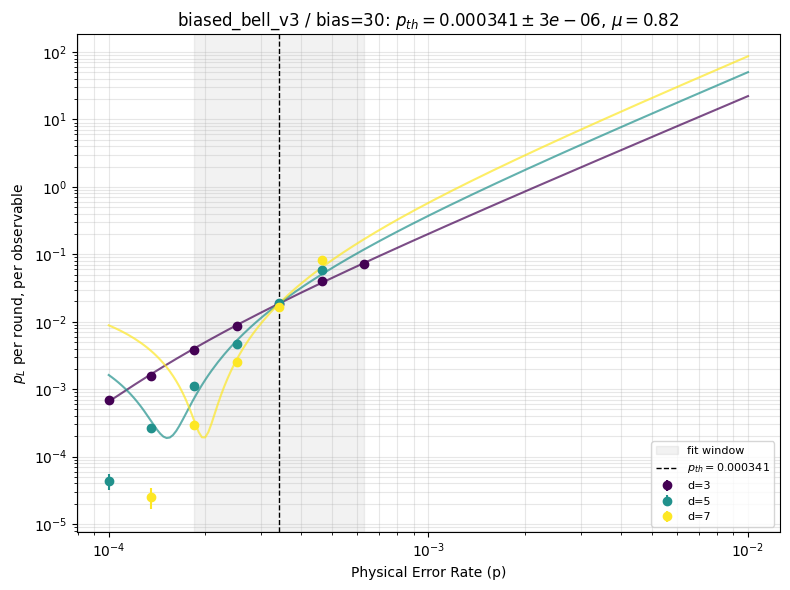

In [10]:
# Diagnostic plot for a single (noise_model, direction): re-run the fit, then plot
# - data points (per distance, with binomial errorbars)
# - the fitted FSS curves
# - the fit window (shaded) and p_th (vertical line)
#
# Useful when a fit looks off (e.g. bias=30) and you want to see whether
# it's the window, the data, or the model.

DIAG_NOISE_MODEL = 'biased_bell_v3'  # change to inspect v2 or v3
DIAG_DIRECTION = 'bias=30'           # change to inspect another direction
DIAG_N_PER_SIDE = N_PER_SIDE
DIAG_LOGICAL_CUTOFF = LOGICAL_CUTOFF

grp = df[(df['noise_model'] == DIAG_NOISE_MODEL) & (df['direction'] == DIAG_DIRECTION)]
if grp.empty:
    raise ValueError(
        f'No rows for ({DIAG_NOISE_MODEL!r}, {DIAG_DIRECTION!r}). '
        f'Available directions for {DIAG_NOISE_MODEL!r}: '
        f'{sorted(df[df["noise_model"] == DIAG_NOISE_MODEL]["direction"].unique())}'
    )

p_arr = grp['p'].to_numpy(dtype=float)
d_arr = grp['expected_distance'].to_numpy(dtype=float)
rounds_arr = grp['rounds'].to_numpy(dtype=float)
k_arr = grp['k'].to_numpy(dtype=float)
shots_arr = grp['shots'].to_numpy(dtype=float)
errors_arr = grp['errors'].to_numpy(dtype=float)

valid = (
    (shots_arr > 0)
    & (errors_arr > 0)
    & (errors_arr < shots_arr * DIAG_LOGICAL_CUTOFF)
)
pL_total = np.where(valid, errors_arr / np.maximum(shots_arr, 1), np.nan)
sigma_total = np.where(
    valid,
    np.sqrt(np.clip(pL_total * (1 - pL_total), 0, None) / np.maximum(shots_arr, 1)),
    np.nan,
)
scale = d_arr / (rounds_arr * np.maximum(k_arr, 1))
pL = 1 - (1 - pL_total) ** scale
sigma = sigma_total * scale * (1 - pL_total) ** (scale - 1)

p_init = locate_threshold(p_arr, d_arr, pL)
fit = fit_threshold(p_arr, d_arr, pL, sigma=sigma, p_init=p_init, n_per_side=DIAG_N_PER_SIDE)

print(f'p_init  = {p_init:.4g}')
print(f'p_th    = {fit.p_th:.4g} +/- {fit.p_th_err:.2g}')
print(f'mu      = {fit.mu:.3g} +/- {fit.mu_err:.2g}')
print(f'window  = {fit.p_window}')
print(f'n_points (in fit) = {fit.n_points}')

fig, ax = plt.subplots(figsize=(8, 6))

distances = sorted(np.unique(d_arr[np.isfinite(d_arr)]))
cmap = plt.get_cmap('viridis')
colors = {d: cmap(i / max(1, len(distances) - 1)) for i, d in enumerate(distances)}

# Smooth p grid for the fit overlay.
finite_p = p_arr[(p_arr > 0) & np.isfinite(p_arr)]
p_smooth = np.geomspace(finite_p.min(), finite_p.max(), 200)

for d in distances:
    mask = (d_arr == d) & np.isfinite(pL) & (pL > 0)
    ax.errorbar(
        p_arr[mask], pL[mask], yerr=sigma[mask],
        fmt='o', color=colors[d], label=f'd={int(d)}',
    )
    ax.plot(
        p_smooth, fit.predict(p_smooth, np.full_like(p_smooth, d)),
        color=colors[d], linestyle='-', alpha=0.7,
    )

# Shade the fit window.
w_lo, w_hi = min(fit.p_window), max(fit.p_window)
ax.axvspan(w_lo, w_hi, alpha=0.1, color='gray', label='fit window')
ax.axvline(fit.p_th, color='k', linestyle='--', linewidth=1,
           label=f'$p_{{th}}={fit.p_th:.3g}$')

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('Physical Error Rate (p)')
ax.set_ylabel(r'$p_L$ per round, per observable')
ax.set_title(
    f"{DIAG_NOISE_MODEL} / {DIAG_DIRECTION}: "
    f"$p_{{th}}={fit.p_th:.3g} \\pm {fit.p_th_err:.1g}$, "
    f"$\\mu={fit.mu:.2g}$"
)
ax.grid(True, alpha=0.3, which='both')
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

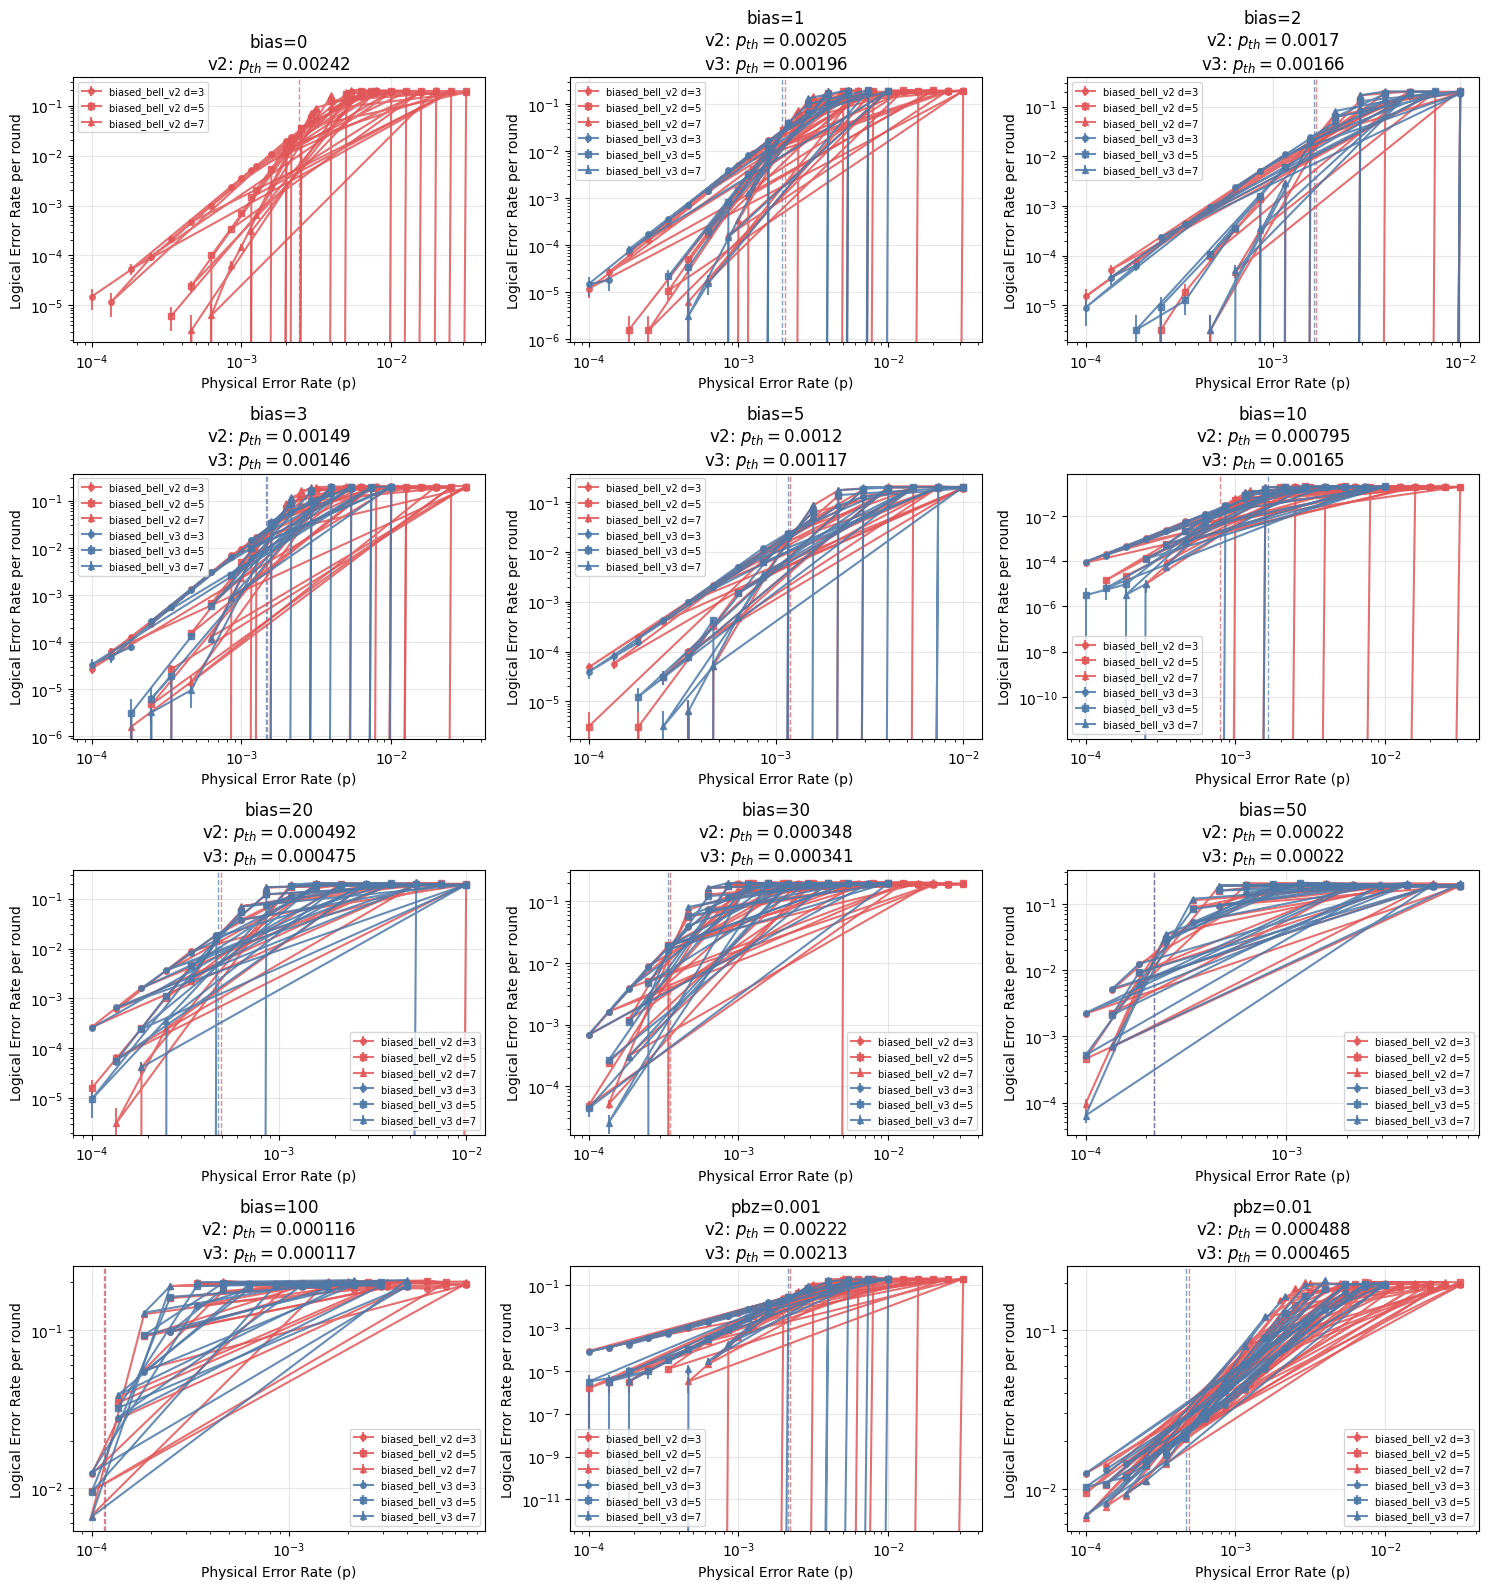

In [11]:
# Per-direction logical-error-rate curves, with the fitted threshold drawn
# as a vertical dashed line. Both noise models overlaid: color encodes the
# noise model, marker encodes the distance.

NOISE_MODEL_COLORS = {
    'biased_bell_v2': '#e15759',  # red-ish
    'biased_bell_v3': '#4e79a7',  # blue-ish
}
DISTANCE_MARKERS = {2: 'o', 3: 'o', 4: 's', 5: 's', 6: '^', 7: '^'}

# Stable ordering: biases ascending, then fixed-pbz ascending.
def _direction_sort_key(d):
    sub = df[df['direction'] == d].iloc[0]
    if sub['direction_kind'] == 'bias':
        return (0, float(sub['bias']))
    return (1, float(sub['p_bell_z_fixed']))

direction_names = sorted(df['direction'].unique(), key=_direction_sort_key)
present_models = [m for m in NOISE_MODELS if m in df['noise_model'].unique()]

fits_lookup = {}
if not fits_df.empty:
    fits_lookup = {
        (row['noise_model'], row['direction']): row.to_dict()
        for _, row in fits_df.iterrows()
    }

n = len(direction_names)
ncols = 3
nrows = (n + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows), squeeze=False)

for idx, direction_name in enumerate(direction_names):
    ax = axes[idx // ncols][idx % ncols]

    for model in present_models:
        sub = df[(df['noise_model'] == model) & (df['direction'] == direction_name)]
        if sub.empty:
            continue
        color = NOISE_MODEL_COLORS.get(model, 'k')

        # Convert per-circuit error rate to per-round, per-observable pL,
        # so the y-axis matches the fitted FSS pL.
        scale = sub['expected_distance'] / (
            sub['rounds'] * sub['k'].clip(lower=1)
        )
        pL_total = sub['errors'] / sub['shots'].clip(lower=1)
        pL = 1 - (1 - pL_total) ** scale
        sigma_total = np.sqrt(
            np.clip(pL_total * (1 - pL_total), 0, None) / sub['shots'].clip(lower=1)
        )
        sigma = sigma_total * scale * (1 - pL_total) ** (scale - 1)

        for d, sub_d in sub.groupby('expected_distance'):
            mask = sub_d.index
            ax.errorbar(
                sub_d['p'], pL.loc[mask], yerr=sigma.loc[mask],
                fmt=DISTANCE_MARKERS.get(int(d), 'o') + '-',
                color=color, alpha=0.85, markersize=4,
                label=f'{model} d={int(d)}',
            )

        fit = fits_lookup.get((model, direction_name))
        if fit is not None and np.isfinite(fit['p_th']):
            ax.axvline(fit['p_th'], color=color, linestyle='--', linewidth=1, alpha=0.7)

    # Title combines fits from both models when available.
    parts = [direction_name]
    for model in present_models:
        fit = fits_lookup.get((model, direction_name))
        if fit is not None and np.isfinite(fit['p_th']):
            parts.append(
                f"{model.replace('biased_bell_', '')}: "
                f"$p_{{th}}={fit['p_th']:.3g}$"
            )
    ax.set_title('\n'.join(parts))

    ax.loglog()
    ax.set_xlabel('Physical Error Rate (p)')
    ax.set_ylabel('Logical Error Rate per round')
    ax.legend(fontsize=7)
    ax.grid(True, alpha=0.3)

for idx in range(len(direction_names), nrows * ncols):
    axes[idx // ncols][idx % ncols].axis('off')

fig.tight_layout()
plt.show()

In [12]:
# Persist fits for the threshold-vs-bias notebook.
out_path = Path('../out/collection/threshold_bell_fits.csv')
fits_df.to_csv(out_path, index=False)
print(f'Saved fits -> {out_path}')
fits_df

Saved fits -> ../out/collection/threshold_bell_fits.csv


,noise_model,direction,direction_kind,bias,p_bell_z_fixed,p_th,p_th_err,mu,mu_err,p_init,n_points
0,biased_bell_v2,bias=0,bias,0.0,NaN,0.002418,2.159251e-05,0.910499,0.044097,0.002512,15
1,biased_bell_v2,bias=1,bias,1.0,NaN,0.002047,1.233021e-05,0.971927,0.035426,0.002154,14
2,biased_bell_v2,bias=2,bias,2.0,NaN,0.001701,2.051408e-05,0.756509,0.026000,0.001585,13
3,biased_bell_v2,bias=3,bias,3.0,NaN,0.001486,9.182376e-06,0.954573,0.026916,0.001585,14
4,biased_bell_v2,bias=5,bias,5.0,NaN,0.001196,1.259919e-05,0.815859,0.025822,0.001166,13
5,biased_bell_v2,bias=10,bias,10.0,NaN,0.000795,4.923095e-06,0.880964,0.021115,0.000858,14
6,biased_bell_v2,bias=20,bias,20.0,NaN,0.000492,6.146875e-06,0.713299,0.025259,0.000464,13
7,biased_bell_v2,bias=30,bias,30.0,NaN,0.000348,2.581181e-06,0.791440,0.017868,0.000341,13
8,biased_bell_v2,bias=50,bias,50.0,NaN,0.000220,1.991365e-06,0.884524,0.030904,0.000251,12
9,biased_bell_v2,bias=100,bias,100.0,NaN,0.000116,8.823396e-07,0.963759,0.036348,0.000136,9
